# Square-wave illusion: simulation and inverse rendering

Group/professor review draft, 22 October 2026. All six computational steps are implemented. This notebook explains the renderer and loads the saved optimization results; it does not silently run a long search. The target is provisional. See docs/METHODS.md and docs/PROFESSOR_REVIEW.md.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from model import Surface, example_surface, sphere_directions, light_direction, render, triangle_target
from validate import run_checks
from fit import decode
root = Path.cwd()

## 1. Surface geometry

N heights form a periodic, piecewise planar cross-section. The surface extends along Y. Height values are not luminance values. The last segment joins the next cycle.

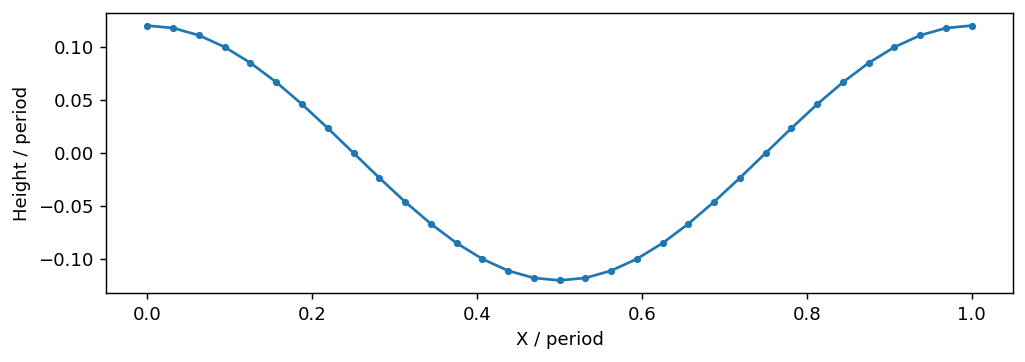

In [2]:
surface = example_surface("sinusoid", segments=32, amplitude=0.12)
plt.figure(figsize=(9, 2.8))
plt.plot(np.arange(33)/32, np.r_[surface.heights, surface.heights[0]], ".-")
plt.xlabel("X / period"); plt.ylabel("Height / period"); plt.show()

## 2. Lighting, shadows, and Lambertian output

Light vectors point toward the source. A source at azimuth 180 degrees is on the left. Kappa zero means uniform illumination; higher values concentrate the light. A single segment can be partially shadowed, so several positions are sampled.

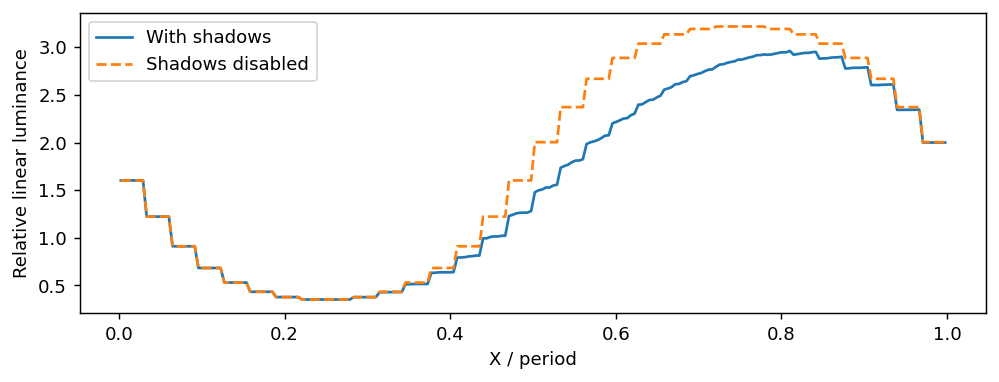

In [3]:
directions = sphere_directions(4096)
mean_light = light_direction(180, 30)
x, luminance = render(surface, directions, mean_light, 8, samples_per_segment=7)
_, no_shadows = render(surface, directions, mean_light, 8, samples_per_segment=7, shadows=False)
plt.figure(figsize=(9,3))
plt.plot(x, luminance, label="With shadows")
plt.plot(x, no_shadows, "--", label="Shadows disabled")
plt.xlabel("X / period"); plt.ylabel("Relative linear luminance"); plt.legend(); plt.show()

## 3. Physical checks

These include an independent ray-intersection check, a flat-surface analytic case, light normalization, and invariances.

In [4]:
checks = run_checks()
for name, passed in checks.items():
    print(("PASS" if passed else "FAIL"), name)
assert all(checks.values())

PASS unit_sphere_vectors
PASS flat_uniform_radiance_is_one
PASS vmf_normalization_kappa_0
PASS vmf_normalization_kappa_1
PASS vmf_normalization_kappa_8
PASS vmf_normalization_kappa_30
PASS overhead_light_unblocked
PASS overhead_cosine_law
PASS light_from_below_blocked
PASS horizons_match_independent_ray_intersections
PASS test_case_contains_cast_shadows
PASS vertical_translation_invariance
PASS ridge_direction_reflection_invariance
PASS shadows_cannot_increase_direct_radiance
PASS nonnegative_output


## 4. Inverse rendering

The optimizer adjusts geometry and three lighting parameters to match the provisional triangle wave. It fixes mean height to zero, uses fixed total angular radiance, and adds a small curvature penalty. Four geometry families are compared. Read saved results below; to reproduce the searches separately, run `python run_all.py --full`.

In [5]:
analysis = json.loads((root / "results/optimization/analysis.json").read_text())
assert analysis["status"] == "complete"
for record in analysis["selected_fits"]:
    scores = record["evaluation_metrics"]
    print(f"{record['family']:12s} RMSE={scores['rmse']:.5f}  MAE={scores['mae']:.5f}  R²={scores['r_squared']:.4f}")
print("Evaluation uses 16,384 directions and 15 samples per segment.")

flat         RMSE=0.34640  MAE=0.30000  R²=-0.0000
sinusoid     RMSE=0.05928  MAE=0.04822  R²=0.9707
square_like  RMSE=0.14801  MAE=0.11537  R²=0.8174
free         RMSE=0.04155  MAE=0.03588  R²=0.9856
Evaluation uses 16,384 directions and 15 samples per segment.


## 5. Inspect a fitted candidate

The free surface is not constrained to be a rectangular square wave. A good luminance match does not prove that the shape is the one perceived by observers.

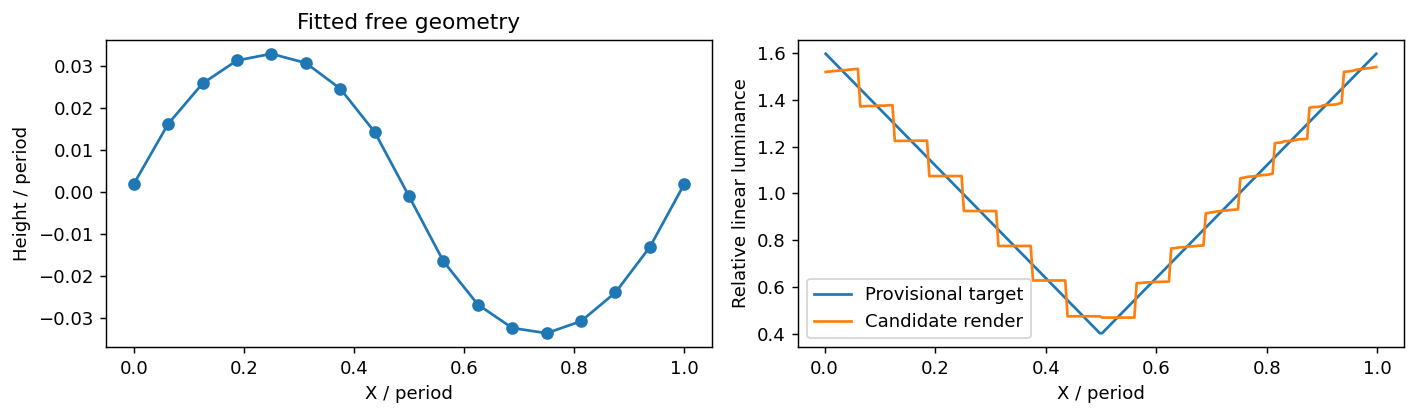

Lighting: {'azimuth_deg': 140.7033964758348, 'elevation_deg': 14.555426115398458, 'kappa': 21.627786492057073}


In [6]:
best = next(r for r in analysis["selected_fits"] if r["family"] == "free")
fitted, mu, kappa = decode(best["parameters"], "free", analysis["config"]["segments"])
x, y = render(fitted, sphere_directions(16384), mu, kappa, samples_per_segment=15)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
axes[0].plot(np.arange(17)/16, np.r_[fitted.heights, fitted.heights[0]], "o-")
axes[0].set(xlabel="X / period", ylabel="Height / period", title="Fitted free geometry")
axes[1].plot(x, triangle_target(x), label="Provisional target")
axes[1].plot(x, y, label="Candidate render")
axes[1].set(xlabel="X / period", ylabel="Relative linear luminance")
axes[1].legend(); plt.tight_layout(); plt.show()
print("Lighting:", {key: best[key] for key in ("azimuth_deg", "elevation_deg", "kappa")})

## 6. Numerical resolution and sensitivity

Midpoint-only evaluation can make the fit look almost exact while hiding variation within segments. Increasing N changes geometry flexibility; increasing the direction count checks the light integral for a fixed geometry. The N=32 case below is one additional warm-started search, not a three-seed comparison.

In [7]:
print("Within-segment sampling (same N=16 fit):")
for row in analysis["convergence"]:
    if row["varied"] == "samples_per_segment":
        print(f"{row['value']:2d} samples: RMSE {row['rmse']:.5f}")
print("Sensitivity cases:")
for record in analysis["sensitivity"]:
    print(f"{record['label']:20s} RMSE {record['evaluation_metrics']['rmse']:.5f}")

Within-segment sampling (same N=16 fit):
 1 samples: RMSE 0.00215
 3 samples: RMSE 0.03931
 5 samples: RMSE 0.04084
 7 samples: RMSE 0.04118
15 samples: RMSE 0.04155
31 samples: RMSE 0.04162
Sensitivity cases:
N8                   RMSE 0.08322
N32                  RMSE 0.02110
no_smoothness        RMSE 0.04158
stronger_smoothness  RMSE 0.04156
kappa60              RMSE 0.04154


## 7. Limits and next decisions

The global free-surface searches reached iteration limits; local Powell termination does not prove global optimality. The model excludes interreflection and overhangs. Shape and light are not uniquely identifiable from one profile. No participant study has been run. Confirm the exact target, admissible shapes, lighting constraints, and acceptable error with the professor before final course interpretation. See docs/RESULTS.md for the full findings and docs/PROFESSOR_REVIEW.md for the checklist.